<a href="https://colab.research.google.com/github/bunjiro1213/gtzan-music-genre-classification/blob/main/GTZAN_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
!pip install -q kagglehub librosa soundfile

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import torch
import kagglehub
from pathlib import Path
path = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)
data_path = Path(path)
print("Dataset location:", data_path)
print("GPU available:", torch.cuda.is_available())

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Dataset location: /kaggle/input/gtzan-dataset-music-genre-classification
GPU available: True


In [13]:
audio_files = sorted(data_path.rglob("*.wav"))
print("Number of audio files:", len(audio_files))
print("First five audio files:")
for file in audio_files[:5]:
    print(file)

Number of audio files: 1000
First five audio files:
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00000.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00001.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00002.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00003.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00004.wav


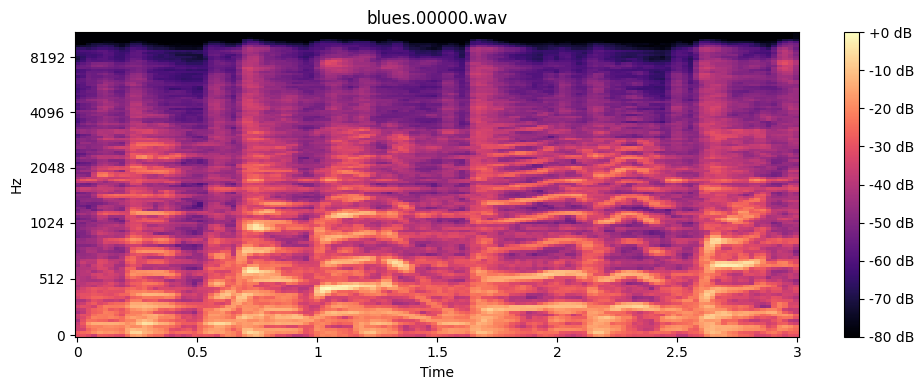

Spectrogram shape: (128, 130)


In [14]:
audio_file = audio_files[0]
y, sr = librosa.load(audio_file, sr=22050)
# Take first 3 seconds
segment = y[:3 * sr]
# Convert into mel spectrogram
mel = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)
mel_db = librosa.power_to_db(mel, ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)
plt.colorbar(format="%+2.0f dB")
plt.title(audio_file.name)
plt.tight_layout()
plt.show()
print("Spectrogram shape:", mel_db.shape)

In [15]:
window_size = 3 * sr
spectrograms = []
for i in range(10):
    start = i * window_size
    end = start + window_size
    segment = y[start:end]
    if len(segment) < window_size:
        break
    mel = librosa.feature.melspectrogram(
        y=segment,
        sr=sr,
        n_mels=128,
        n_fft=2048,
        hop_length=512
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    spectrograms.append(mel_db)

spectrograms = np.array(spectrograms)
print("Number of windows:", len(spectrograms))
print("Spectrograms shape:", spectrograms.shape)

Number of windows: 10
Spectrograms shape: (10, 128, 130)


In [16]:
import torch
X = torch.tensor(spectrograms, dtype=torch.float32)
# Add channel dimension
X = X.unsqueeze(1)
print("CNN input shape:", X.shape)

CNN input shape: torch.Size([10, 1, 128, 130])


In [17]:
import torch.nn as nn

class GenreCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(32, 10)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [18]:
model = GenreCNN()
output = model(X)
print("Input shape:", X.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([10, 1, 128, 130])
Output shape: torch.Size([10, 10])


In [19]:
def process_song(audio_file):
    y, sr = librosa.load(audio_file, sr=22050, duration=30)
    window_size = 3 * sr
    # Make sure every song has 30 seconds of audio
    if len(y) < 10 * window_size:
        y = np.pad(y, (0, 10 * window_size - len(y)))
    spectrograms = []
    for i in range(10):
        start = i * window_size
        end = start + window_size
        segment = y[start:end]
        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_mels=128,
            n_fft=2048,
            hop_length=512
        )
        mel_db = librosa.power_to_db(mel, ref=1.0)
        spectrograms.append(mel_db)
    return np.array(spectrograms, dtype=np.float32)

In [20]:
for audio_file in audio_files[:5]:
    result = process_song(audio_file)
    print(audio_file.name, result.shape)

blues.00000.wav (10, 128, 130)
blues.00001.wav (10, 128, 130)
blues.00002.wav (10, 128, 130)
blues.00003.wav (10, 128, 130)
blues.00004.wav (10, 128, 130)


In [21]:
from google.colab import files
uploaded = files.upload()
manifest = pd.read_csv("split_manifest.csv")
print(manifest.head())
print(manifest["split"].value_counts())

Saving split_manifest.csv to split_manifest.csv
          filename  label  split
0  blues.00000.wav  blues  train
1  blues.00001.wav  blues   test
2  blues.00002.wav  blues   test
3  blues.00003.wav  blues  train
4  blues.00004.wav  blues  train
split
train    639
test     200
val      160
Name: count, dtype: int64


In [22]:
audio_by_name = {file.name: file for file in audio_files}
missing = [
    filename for filename in manifest["filename"]
    if filename not in audio_by_name
]
print("Missing audio files:", missing)
print("Number of songs:", len(manifest))

Missing audio files: []
Number of songs: 999


In [23]:
from tqdm.auto import tqdm
genres = sorted(manifest["label"].unique())
genre_to_id = {genre: i for i, genre in enumerate(genres)}
data = {}
for split in ["train", "val", "test"]:
    rows = manifest[manifest["split"] == split]
    X_list = []
    y_list = []
    for row in tqdm(rows.itertuples(index=False), total=len(rows), desc=split):
        audio_file = audio_by_name[row.filename]
        spectrograms = process_song(audio_file)
        X_list.append(spectrograms)
        y_list.append(genre_to_id[row.label])
    X = np.stack(X_list)
    y = np.array(y_list)
    data[split] = (X, y)
    print(split, X.shape, y.shape)

train:   0%|          | 0/639 [00:00<?, ?it/s]

train (639, 10, 128, 130) (639,)


val:   0%|          | 0/160 [00:00<?, ?it/s]

val (160, 10, 128, 130) (160,)


test:   0%|          | 0/200 [00:00<?, ?it/s]

test (200, 10, 128, 130) (200,)


In [24]:
from torch.utils.data import TensorDataset, DataLoader
train_X = data["train"][0]
mean = train_X.mean()
std = train_X.std() + 1e-8
def create_loader(split, batch_size=32):
    X, y = data[split]
    X = (X - mean) / std
    # Convert songs into individual windows
    X = X.reshape(-1, 1, 128, 130)
    y = np.repeat(y, 10)
    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.long)
    dataset = TensorDataset(X, y)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=(split == "train")
    )
train_loader = create_loader("train")
val_loader = create_loader("val")
test_loader = create_loader("test")
print("Training windows:", len(train_loader.dataset))
print("Validation windows:", len(val_loader.dataset))
print("Testing windows:", len(test_loader.dataset))

Training windows: 6390
Validation windows: 1600
Testing windows: 2000


In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
model = GenreCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Using device: cuda


In [27]:
import copy
num_epochs = 15
patience = 4
best_val_loss = float("inf")
best_model = None
epochs_without_improvement = 0
for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for X, y in train_loader:
        X = X.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * y.size(0)
        train_correct += (outputs.argmax(dim=1) == y).sum().item()
        train_total += y.size(0)

    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for X, y in val_loader:
            X = X.to(device)
            y = y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            val_loss += loss.item() * y.size(0)
            val_correct += (outputs.argmax(dim=1) == y).sum().item()
            val_total += y.size(0)

    train_loss /= train_total
    val_loss /= val_total
    train_acc = train_correct / train_total
    val_acc = val_correct / val_total
    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )
    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break
# Restore best model
model.load_state_dict(best_model)

Epoch 1/15 | Train Loss: 2.0975 | Train Acc: 0.2056 | Val Loss: 1.9742 | Val Acc: 0.3038
Epoch 2/15 | Train Loss: 1.9213 | Train Acc: 0.2911 | Val Loss: 1.7968 | Val Acc: 0.4094
Epoch 3/15 | Train Loss: 1.8045 | Train Acc: 0.3346 | Val Loss: 1.6764 | Val Acc: 0.4394
Epoch 4/15 | Train Loss: 1.7088 | Train Acc: 0.3757 | Val Loss: 1.5828 | Val Acc: 0.4750
Epoch 5/15 | Train Loss: 1.6531 | Train Acc: 0.3992 | Val Loss: 1.5030 | Val Acc: 0.5025
Epoch 6/15 | Train Loss: 1.6249 | Train Acc: 0.4078 | Val Loss: 1.4628 | Val Acc: 0.4994
Epoch 7/15 | Train Loss: 1.5772 | Train Acc: 0.4249 | Val Loss: 1.4205 | Val Acc: 0.5131
Epoch 8/15 | Train Loss: 1.5614 | Train Acc: 0.4346 | Val Loss: 1.3931 | Val Acc: 0.5162
Epoch 9/15 | Train Loss: 1.5390 | Train Acc: 0.4366 | Val Loss: 1.3677 | Val Acc: 0.5244
Epoch 10/15 | Train Loss: 1.5234 | Train Acc: 0.4341 | Val Loss: 1.3554 | Val Acc: 0.5175
Epoch 11/15 | Train Loss: 1.5072 | Train Acc: 0.4499 | Val Loss: 1.3298 | Val Acc: 0.5250
Epoch 12/15 | Train

<All keys matched successfully>

In [28]:
torch.save({
    "model_state_dict": model.state_dict(),
    "genres": genres,
    "mean": float(mean),
    "std": float(std)
}, "genre_cnn_best.pt")
print("Model saved successfully!")

Model saved successfully!


In [29]:
model.eval()
all_probs = []
with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        outputs = model(X)
        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu())

# Combine predictions from all validation windows
all_probs = torch.cat(all_probs)
print("Window probabilities shape:", all_probs.shape)
# Group every 10 windows back into one song
song_probs = all_probs.reshape(-1, 10, 10).mean(dim=1)
# Choose the genre with the highest average probability
song_predictions = song_probs.argmax(dim=1).numpy()
# Actual song labels
song_labels = data["val"][1]
# Calculate song-level accuracy
song_accuracy = np.mean(song_predictions == song_labels)
print("Song-level validation accuracy:", round(song_accuracy * 100, 2), "%")

Window probabilities shape: torch.Size([1600, 10])
Song-level validation accuracy: 54.37 %


In [30]:
from sklearn.metrics import accuracy_score
# Window-level predictions
window_predictions = all_probs.argmax(dim=1).numpy()
window_labels = np.repeat(song_labels, 10)
window_accuracy = accuracy_score(
    window_labels, window_predictions
)
song_accuracy = accuracy_score(
    song_labels, song_predictions
)
print(f"Window-level accuracy: {window_accuracy:.2%}")
print(f"Song-level accuracy: {song_accuracy:.2%}")

Window-level accuracy: 53.69%
Song-level accuracy: 54.37%


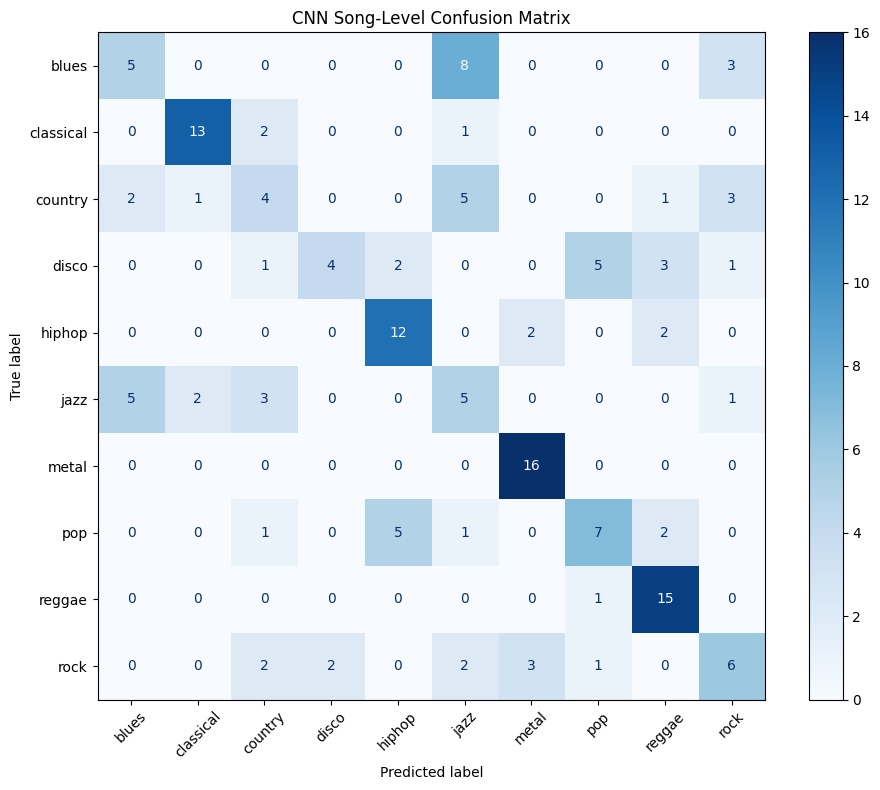

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(song_labels, song_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=genres
)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CNN Song-Level Confusion Matrix")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.metrics import classification_report
print(classification_report(
    song_labels,
    song_predictions,
    labels=range(len(genres)),
    target_names=genres,
    zero_division=0
))

              precision    recall  f1-score   support

       blues       0.42      0.31      0.36        16
   classical       0.81      0.81      0.81        16
     country       0.31      0.25      0.28        16
       disco       0.67      0.25      0.36        16
      hiphop       0.63      0.75      0.69        16
        jazz       0.23      0.31      0.26        16
       metal       0.76      1.00      0.86        16
         pop       0.50      0.44      0.47        16
      reggae       0.65      0.94      0.77        16
        rock       0.43      0.38      0.40        16

    accuracy                           0.54       160
   macro avg       0.54      0.54      0.53       160
weighted avg       0.54      0.54      0.53       160



In [33]:
val_rows = manifest[manifest["split"] == "val"].reset_index(drop=True)
results = pd.DataFrame({
    "filename": val_rows["filename"],
    "actual": [genres[i] for i in song_labels],
    "predicted": [genres[i] for i in song_predictions],
    "confidence": song_probs.max(dim=1).values.numpy()
})
mistakes = results[results["actual"] != results["predicted"]]
print("Number of incorrect predictions:", len(mistakes))
display(mistakes.head(20))

Number of incorrect predictions: 73


,filename,actual,predicted,confidence
2,blues.00018.wav,blues,jazz,0.309034
4,blues.00030.wav,blues,jazz,0.304256
5,blues.00033.wav,blues,jazz,0.361745
6,blues.00034.wav,blues,jazz,0.303758
7,blues.00035.wav,blues,jazz,0.307834
8,blues.00038.wav,blues,jazz,0.318695
9,blues.00041.wav,blues,rock,0.255281
10,blues.00045.wav,blues,rock,0.213675
12,blues.00084.wav,blues,rock,0.223982
13,blues.00085.wav,blues,jazz,0.301006


In [34]:
torch.save({
    "model_state_dict": model.state_dict(),
    "genres": genres,
    "mean": float(mean),
    "std": float(std)
}, "genre_cnn_v1.pt")

baseline_window_acc = 0.5088
baseline_song_acc = 0.5625
print("Baseline model saved!")

Baseline model saved!


In [35]:
class GenreCNNv2(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((2, 2))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 10)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [36]:
# Initialize CNN v2
model = GenreCNNv2().to(device)
# Set up loss and optimizer for the NEW model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print("CNN v2 initialized!")
print("Using device:", device)

CNN v2 initialized!
Using device: cuda


In [38]:
import copy
num_epochs = 15
patience = 4
best_val_loss = float("inf")
best_model = None
epochs_without_improvement = 0
for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for X, y in train_loader:
        X = X.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * y.size(0)
        train_correct += (outputs.argmax(dim=1) == y).sum().item()
        train_total += y.size(0)
    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for X, y in val_loader:
            X = X.to(device)
            y = y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            val_loss += loss.item() * y.size(0)
            val_correct += (outputs.argmax(dim=1) == y).sum().item()
            val_total += y.size(0)

    train_loss /= train_total
    val_loss /= val_tota
    train_acc = train_correct / train_total
    val_acc = val_correct / val_total
    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore best model
model.load_state_dict(best_model)

Epoch 1/15 | Train Loss: 1.7101 | Train Acc: 0.3853 | Val Loss: 1.3108 | Val Acc: 0.5363
Epoch 2/15 | Train Loss: 1.3626 | Train Acc: 0.5095 | Val Loss: 1.1960 | Val Acc: 0.5725
Epoch 3/15 | Train Loss: 1.2089 | Train Acc: 0.5662 | Val Loss: 1.0025 | Val Acc: 0.6212
Epoch 4/15 | Train Loss: 1.1080 | Train Acc: 0.6047 | Val Loss: 1.0092 | Val Acc: 0.6306
Epoch 5/15 | Train Loss: 1.0419 | Train Acc: 0.6324 | Val Loss: 0.8033 | Val Acc: 0.7194
Epoch 6/15 | Train Loss: 0.9670 | Train Acc: 0.6568 | Val Loss: 1.3574 | Val Acc: 0.5244
Epoch 7/15 | Train Loss: 0.8996 | Train Acc: 0.6806 | Val Loss: 0.8104 | Val Acc: 0.7037
Epoch 8/15 | Train Loss: 0.8548 | Train Acc: 0.7061 | Val Loss: 0.7663 | Val Acc: 0.7231
Epoch 9/15 | Train Loss: 0.8337 | Train Acc: 0.7022 | Val Loss: 0.7425 | Val Acc: 0.7362
Epoch 10/15 | Train Loss: 0.7944 | Train Acc: 0.7249 | Val Loss: 0.9717 | Val Acc: 0.6856
Epoch 11/15 | Train Loss: 0.7414 | Train Acc: 0.7371 | Val Loss: 0.7856 | Val Acc: 0.7212
Epoch 12/15 | Train

<All keys matched successfully>

In [39]:
torch.save({
    "model_state_dict": model.state_dict(),
    "genres": genres,
    "mean": float(mean),
    "std": float(std)
}, "genre_cnn_v2.pt")

print("CNN v2 saved successfully!")

CNN v2 saved successfully!


CNN V1 vs CNN V2
------------------------
V1 Window Accuracy: 50.88%
V2 Window Accuracy: 73.62%

V1 Song Accuracy: 56.25%
V2 Song Accuracy: 80.62%

CNN V2 Classification Report:
              precision    recall  f1-score   support

       blues       0.85      0.69      0.76        16
   classical       1.00      0.94      0.97        16
     country       0.50      0.88      0.64        16
       disco       0.75      0.75      0.75        16
      hiphop       1.00      0.75      0.86        16
        jazz       0.80      1.00      0.89        16
       metal       0.94      0.94      0.94        16
         pop       0.79      0.69      0.73        16
      reggae       1.00      0.94      0.97        16
        rock       0.73      0.50      0.59        16

    accuracy                           0.81       160
   macro avg       0.83      0.81      0.81       160
weighted avg       0.83      0.81      0.81       160



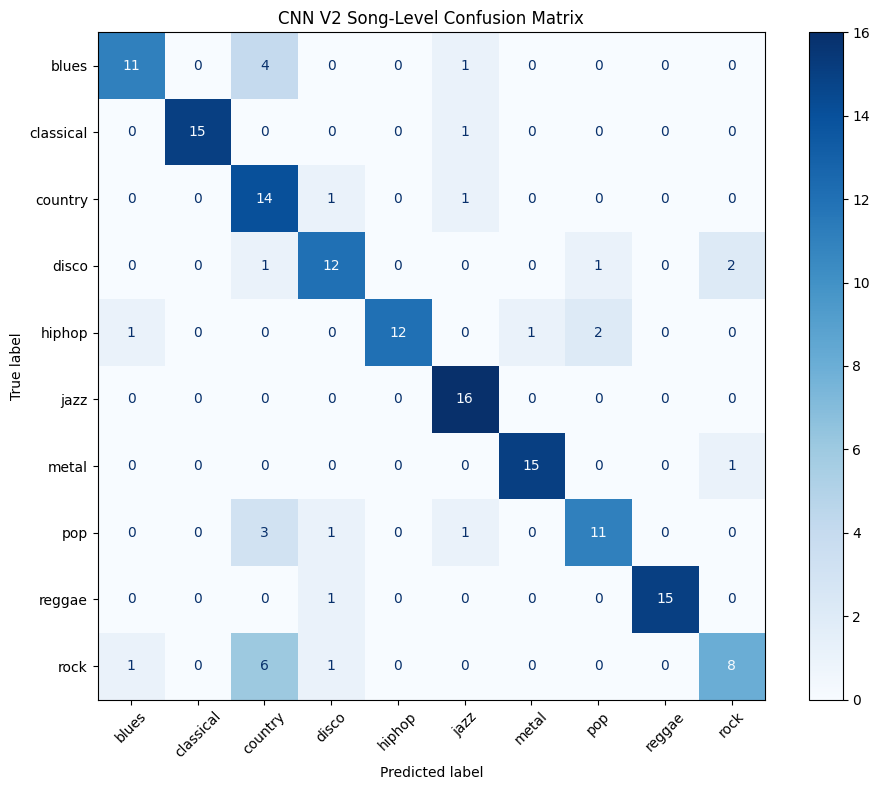

In [41]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Evaluate CNN v2
model.eval()
all_probs = []
with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        outputs = model(X)
        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu())
all_probs = torch.cat(all_probs)

# Window-level accuracy
song_labels = data["val"][1]
window_labels = np.repeat(song_labels, 10)
window_predictions = all_probs.argmax(dim=1).numpy()

window_accuracy_v2 = accuracy_score(
    window_labels, window_predictions
)

# Song-level accuracy
song_probs = all_probs.reshape(-1, 10, 10).mean(dim=1)
song_predictions = song_probs.argmax(dim=1).numpy()
song_accuracy_v2 = accuracy_score(
    song_labels, song_predictions
)

# Compare CNN v1 and CNN v2
print("CNN V1 vs CNN V2")
print("------------------------")
print(f"V1 Window Accuracy: {baseline_window_acc:.2%}")
print(f"V2 Window Accuracy: {window_accuracy_v2:.2%}")
print()
print(f"V1 Song Accuracy: {baseline_song_acc:.2%}")
print(f"V2 Song Accuracy: {song_accuracy_v2:.2%}")

# Classification report
print("\nCNN V2 Classification Report:")
print(classification_report(
    song_labels,
    song_predictions,
    labels=range(len(genres)),
    target_names=genres,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    song_labels,
    song_predictions,
    labels=range(len(genres))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=genres
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("CNN V2 Song-Level Confusion Matrix")
plt.tight_layout()
plt.show()